# Análisis de Ventas E-commerce · SQL + Python
**Autor:** Juan Camilo Castro López · Analista de Datos Jr

**Pregunta de negocio:** ¿Qué categorías, canales y clientes impulsan las ventas de una tienda online de mobiliario, y dónde están las oportunidades para crecer en 2026?

**Flujo:** SQLite (modelo relacional) → consultas SQL (CTEs, funciones de ventana) → pandas → visualización → segmentación RFM → recomendaciones.

> Datos sintéticos generados con `src/generar_datos.py` (semilla fija, reproducible).

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", "{:,.0f}".format)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False})
AZUL, GRIS, NARANJA = "#2a6f97", "#9aa5b1", "#e07a2f"

con = sqlite3.connect("data/ecommerce.db")
for t in ["productos", "clientes", "pedidos", "detalle_pedidos"]:
    print(f"{t:16s}", pd.read_sql(f"SELECT COUNT(*) n FROM {t}", con).n[0])

productos        18
clientes         2500
pedidos          3289
detalle_pedidos  6605


## 1. Calidad de datos
Antes de analizar, verifico nulos, duplicados e integridad referencial.

In [2]:
checks = {
    "pedidos sin cliente válido": "SELECT COUNT(*) FROM pedidos p LEFT JOIN clientes c USING(cliente_id) WHERE c.cliente_id IS NULL",
    "líneas sin producto válido": "SELECT COUNT(*) FROM detalle_pedidos d LEFT JOIN productos p USING(producto_id) WHERE p.producto_id IS NULL",
    "pedidos sin líneas": "SELECT COUNT(*) FROM pedidos p LEFT JOIN detalle_pedidos d USING(pedido_id) WHERE d.pedido_id IS NULL",
    "pedidos duplicados": "SELECT COUNT(*) - COUNT(DISTINCT pedido_id) FROM pedidos",
    "cantidades <= 0": "SELECT COUNT(*) FROM detalle_pedidos WHERE cantidad <= 0",
}
for k, q in checks.items():
    print(f"{k:28s} -> {con.execute(q).fetchone()[0]}")

pedidos sin cliente válido   -> 0
líneas sin producto válido   -> 0
pedidos sin líneas           -> 0
pedidos duplicados           -> 0
cantidades <= 0              -> 0


## 2. Vista de ventas netas y KPIs
La vista `v_ventas` (en `sql/02_consultas_negocio.sql`) une las 3 tablas y considera solo pedidos **entregados**.

In [3]:
sql = open("sql/02_consultas_negocio.sql", encoding="utf-8").read()
vista = sql[sql.index("DROP VIEW"):sql.index("-- Q1")]
con.executescript(vista)

ventas = pd.read_sql("SELECT * FROM v_ventas", con, parse_dates=["fecha"])
ventas["anio"] = ventas.fecha.dt.year

kpi = ventas.groupby("anio").agg(pedidos=("pedido_id", "nunique"), clientes=("cliente_id", "nunique"),
                                ventas=("venta_neta", "sum"), costo=("costo", "sum"))
kpi["ticket_promedio"] = kpi.ventas / kpi.pedidos
kpi["margen_%"] = 100 * (kpi.ventas - kpi.costo) / kpi.ventas
print(kpi.drop(columns="costo").to_string())
print(f"\nCrecimiento de ventas 2025 vs 2024: {100*(kpi.ventas[2025]/kpi.ventas[2024]-1):.1f}%")

      pedidos  clientes        ventas  ticket_promedio  margen_%
anio                                                            
2024      508       371 1,068,272,250        2,102,898        39
2025     2382      1225 5,073,486,000        2,129,927        40

Crecimiento de ventas 2025 vs 2024: 374.9%


## 3. Tendencia mensual y estacionalidad

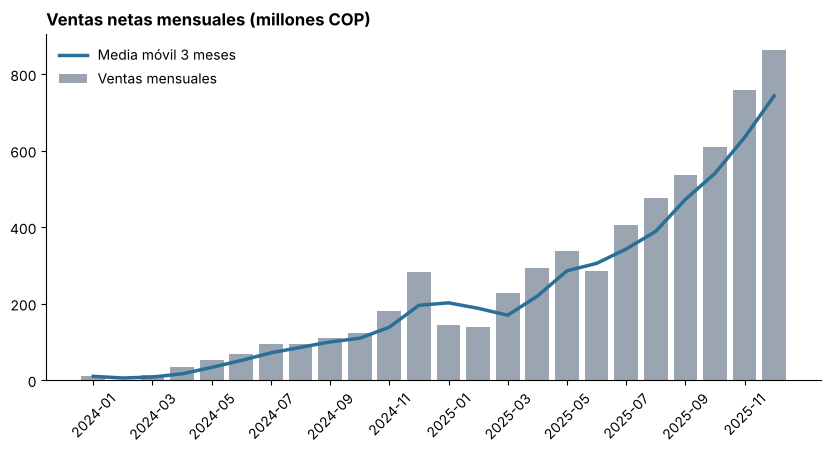

In [4]:
mensual = pd.read_sql("""
WITH m AS (SELECT mes, SUM(venta_neta) v FROM v_ventas GROUP BY mes)
SELECT mes, v AS ventas, AVG(v) OVER (ORDER BY mes ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS media_movil_3m
FROM m ORDER BY mes""", con)

fig, ax = plt.subplots()
ax.bar(mensual.mes, mensual.ventas / 1e6, color=GRIS, label="Ventas mensuales")
ax.plot(mensual.mes, mensual.media_movil_3m / 1e6, color=AZUL, lw=2.5, label="Media móvil 3 meses")
ax.set_title("Ventas netas mensuales (millones COP)", loc="left", fontweight="bold")
ax.set_xticks(mensual.mes[::2]); ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)

In [5]:
v25 = ventas[ventas.anio == 2025]
por_mes = v25.groupby(v25.fecha.dt.month).venta_neta.sum()
print("Participación de nov+dic en ventas 2025: {:.1f}%".format(100 * por_mes.loc[[11, 12]].sum() / por_mes.sum()))

Participación de nov+dic en ventas 2025: 31.9%


## 4. ¿Qué categorías y productos venden más? (Pareto)

 categoria        ventas      margen  margen_pct  pct_acumulado
      Sala 2,011,484,000 772,961,000          38             33
    Alcoba 1,654,089,000 685,126,000          41             60
   Comedor 1,482,010,000 592,680,000          40             84
   Oficina   698,055,500 247,223,500          35             95
Decoración   296,119,750 130,249,750          44            100


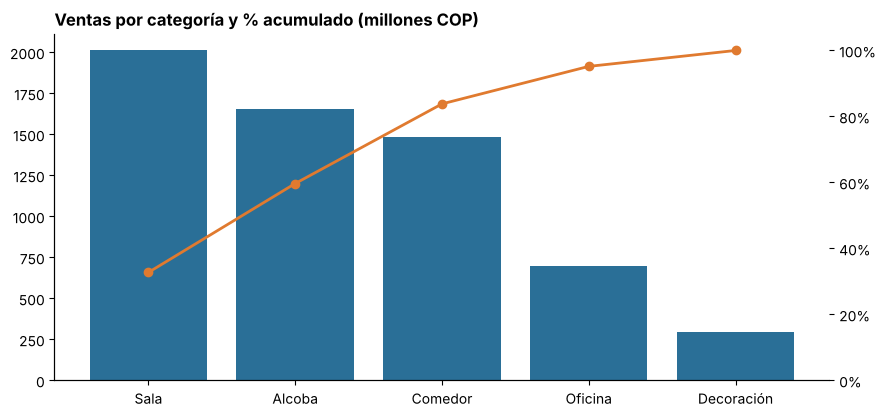

In [6]:
cat = pd.read_sql("""
WITH c AS (SELECT categoria, SUM(venta_neta) ventas, SUM(venta_neta)-SUM(costo) margen FROM v_ventas GROUP BY categoria)
SELECT categoria, ventas, margen, 100.0*margen/ventas AS margen_pct,
       100.0*SUM(ventas) OVER (ORDER BY ventas DESC)/SUM(ventas) OVER () AS pct_acumulado
FROM c ORDER BY ventas DESC""", con)
print(cat.to_string(index=False))

fig, ax = plt.subplots()
ax.bar(cat.categoria, cat.ventas / 1e6, color=AZUL)
ax2 = ax.twinx(); ax2.plot(cat.categoria, cat.pct_acumulado, color=NARANJA, marker="o", lw=2)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.set_ylim(0, 105); ax2.spines["top"].set_visible(False)
ax.set_title("Ventas por categoría y % acumulado (millones COP)", loc="left", fontweight="bold")

In [7]:
top = pd.read_sql(open("sql/02_consultas_negocio.sql", encoding="utf-8").read().split("-- Q3")[1].split("-- Q4")[0].split("\n",1)[1], con)
print(top.to_string(index=False))

 categoria          producto      ventas  ranking
    Alcoba  Closet 3 puertas 618,975,000        1
    Alcoba        Cama doble 517,725,000        2
    Alcoba     Colchón doble 429,275,000        3
   Comedor Comedor 6 puestos 745,775,000        1
   Comedor Comedor 4 puestos 645,200,000        2
   Comedor     Silla comedor  91,035,000        3
Decoración            Tapete 110,704,000        1
Decoración    Lámpara de pie  97,934,000        2
Decoración            Espejo  65,754,000        3
   Oficina        Escritorio 265,484,000        1
   Oficina  Silla ergonómica 256,507,500        2
   Oficina        Biblioteca 176,064,000        3
      Sala    Sofá 3 puestos 884,760,000        1
      Sala         Sofá cama 683,240,000        2
      Sala          Poltrona 266,994,000        3


## 5. Canales de adquisición: ¿cuál trae los mejores clientes?

         canal  clientes        ventas  valor_por_cliente pedidos_por_cliente
      Referido       159   802,262,500          5,045,676                2.42
    Google Ads       297 1,340,772,750          4,514,386                2.10
         Email       109   489,658,250          4,492,278                2.19
Orgánico (SEO)       425 1,876,785,750          4,415,966                2.04
Redes sociales       387 1,632,279,000          4,217,775                2.01


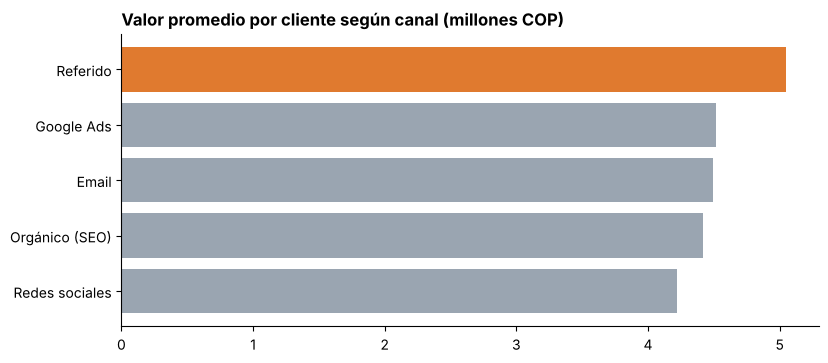

In [8]:
canal = pd.read_sql("""
SELECT c.canal_adquisicion AS canal, COUNT(DISTINCT v.cliente_id) clientes, SUM(v.venta_neta) ventas,
       SUM(v.venta_neta)/COUNT(DISTINCT v.cliente_id) AS valor_por_cliente,
       1.0*COUNT(DISTINCT v.pedido_id)/COUNT(DISTINCT v.cliente_id) AS pedidos_por_cliente
FROM v_ventas v JOIN clientes c USING(cliente_id)
GROUP BY canal ORDER BY valor_por_cliente DESC""", con)
print(canal.to_string(index=False, formatters={"pedidos_por_cliente": "{:.2f}".format}))

fig, ax = plt.subplots(figsize=(9, 3.8))
colores = [NARANJA if c == canal.canal.iloc[0] else GRIS for c in canal.canal]
ax.barh(canal.canal[::-1], canal.valor_por_cliente[::-1] / 1e6, color=colores[::-1])
ax.set_title("Valor promedio por cliente según canal (millones COP)", loc="left", fontweight="bold")

## 6. Cancelaciones y devoluciones por método de pago

In [9]:
pago = pd.read_sql(open("sql/02_consultas_negocio.sql", encoding="utf-8").read().split("-- Q5")[1].split("-- Q6")[0].split("\n",1)[1], con)
pd.set_option("display.float_format", "{:,.1f}".format)
print(pago.to_string(index=False))

    metodo_pago  pedidos  cancelacion_pct  devolucion_pct
  Contraentrega      529              8.3             5.9
            PSE      951              7.5             4.1
Tarjeta crédito     1405              6.8             5.2
          Nequi      404              5.4             5.9


## 7. Segmentación de clientes RFM
Recencia (días desde la última compra), Frecuencia (n.º de pedidos) y Valor monetario. Cada dimensión se puntúa de 1 a 4 por cuartiles.

In [10]:
ref = ventas.fecha.max() + pd.Timedelta(days=1)
rfm = ventas.groupby("cliente_id").agg(recencia=("fecha", lambda s: (ref - s.max()).days),
                                       frecuencia=("pedido_id", "nunique"),
                                       monetario=("venta_neta", "sum"))
rfm["R"] = pd.qcut(rfm.recencia, 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm.frecuencia.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm.monetario, 4, labels=[1, 2, 3, 4]).astype(int)

def segmento(r):
    if r.R >= 3 and r.F >= 3 and r.M >= 3: return "Campeones"
    if r.F >= 3 and r.R >= 2:              return "Leales"
    if r.R >= 3:                           return "Nuevos / prometedores"
    if r.R == 2:                           return "En riesgo"
    return "Perdidos"

rfm["segmento"] = rfm.apply(segmento, axis=1)
seg = rfm.groupby("segmento").agg(clientes=("R", "size"), valor_total=("monetario", "sum"), recencia_media=("recencia", "mean"))
seg["% clientes"] = 100 * seg.clientes / seg.clientes.sum()
seg["% ventas"] = 100 * seg.valor_total / seg.valor_total.sum()
seg = seg.sort_values("% ventas", ascending=False)
print(seg[["clientes", "% clientes", "% ventas", "recencia_media"]].to_string())

                       clientes  % clientes  % ventas  recencia_media
segmento                                                             
Campeones                   358        26.0      49.6            33.6
Leales                      246        17.9      17.6           107.9
Perdidos                    344        25.0      16.3           360.1
Nuevos / prometedores       248        18.0       9.3            46.0
En riesgo                   181        13.1       7.2           146.6


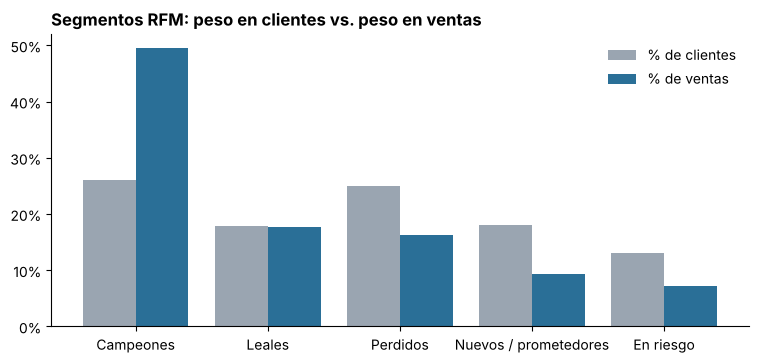

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(seg)); w = 0.4
ax.bar([i - w/2 for i in x], seg["% clientes"], w, color=GRIS, label="% de clientes")
ax.bar([i + w/2 for i in x], seg["% ventas"], w, color=AZUL, label="% de ventas")
ax.set_xticks(list(x)); ax.set_xticklabels(seg.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Segmentos RFM: peso en clientes vs. peso en ventas", loc="left", fontweight="bold")
ax.legend(frameon=False)
rfm.reset_index().to_csv("data/processed/segmentos_rfm.csv", index=False)

## 8. Conclusiones y recomendaciones

1. **Estacionalidad fuerte:** noviembre y diciembre concentran el **31,9%** de las ventas de 2025 (2 de 12 meses) → planear inventario y campañas desde octubre.
2. **Concentración (Pareto):** Sala, Alcoba y Comedor generan el **84%** de los ingresos → priorizar stock y pauta en estas categorías; Decoración (mayor margen, 44%) funciona mejor como venta cruzada.
3. **Canal Referido** trae clientes con un valor promedio **~20% mayor** que Redes sociales y más pedidos por cliente (2,42) → un programa de referidos tiene alto retorno potencial.
4. **Contraentrega** tiene la mayor tasa de cancelación (**8,3%** vs 5,4% de Nequi) → incentivar pagos anticipados con un pequeño descuento.
5. **RFM:** los *Campeones* son el **26%** de los clientes pero aportan el **49,6%** de las ventas; el segmento *En riesgo* (181 clientes, ~147 días sin comprar) es la prioridad para campañas de reactivación por email.

**Siguiente paso:** conectar `data/ecommerce.db` o `data/processed/` a Power BI para un tablero de seguimiento mensual.